<a href="https://www.kaggle.com/code/tarzon/house-price-prediction-advance-regression?scriptVersionId=360390601" target="_blank"><img align="left" alt="Kaggle" title="Open in Kaggle" src="https://kaggle.com/static/images/open-in-kaggle.svg"></a>

# House Price Prediction (Ames Housing)

**Goal:** predict the final `SalePrice` of houses using their features (size, quality, location, age, etc.).

**Type of problem:** supervised learning, regression.

**Evaluation metric:** the Kaggle competition scores **RMSE on log(SalePrice)**. So the log scale is the metric we care about, and we will optimise for it.

**Workflow**
1. Import libraries
2. Load data
3. Understand data
4. Data cleaning
5. Exploratory data analysis (EDA) and outlier handling
6. Feature engineering
7. Preprocessing pipeline
8. Model building and comparison (cross-validation)
9. Hyperparameter tuning
10. Blending and final validation
11. Final model and submission
12. Conclusion and lessons learned

📖 If you want to know why each step is here, read the companion post on Medium: [Predicting House Prices: What My Mistakes Taught Me](https://medium.com/@parulrajput27/predicting-house-prices-what-my-mistakes-taught-me-aa9ef42b549b?source=friends_link&sk=a043e1d08f041a751085bc3c8a5975f2)

## 1. Import Libraries

All imports are kept at the top of the notebook so the whole project is easy to read and re-run.

In [1]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.model_selection import train_test_split, KFold, cross_val_score, cross_val_predict, GridSearchCV
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_squared_error

sns.set_style('whitegrid')
RANDOM_STATE = 42

## 2. Load Dataset

`train.csv` has the target `SalePrice`. `test.csv` does not, because we have to predict it and submit to Kaggle.

In [2]:
train = pd.read_csv('/kaggle/input/competitions/house-prices-advanced-regression-techniques/train.csv')
test = pd.read_csv('/kaggle/input/competitions/house-prices-advanced-regression-techniques/test.csv')

## 3. Understand Data

In [3]:
print("Train shape:", train.shape)
print("Test shape:", test.shape)

Train shape: (1460, 81)
Test shape: (1459, 80)


Train has **81 columns** (80 features plus `SalePrice`) and test has **80** (no target). That difference is expected.

In [4]:
# First few rows of train
train.head()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [5]:
# First few rows of test
test.head()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition
0,1461,20,RH,80.0,11622,Pave,NaN,Reg,Lvl,AllPub,...,120,0,NaN,MnPrv,NaN,0,6,2010,WD,Normal
1,1462,20,RL,81.0,14267,Pave,NaN,IR1,Lvl,AllPub,...,0,0,NaN,NaN,Gar2,12500,6,2010,WD,Normal
2,1463,60,RL,74.0,13830,Pave,NaN,IR1,Lvl,AllPub,...,0,0,NaN,MnPrv,NaN,0,3,2010,WD,Normal
3,1464,60,RL,78.0,9978,Pave,NaN,IR1,Lvl,AllPub,...,0,0,NaN,NaN,NaN,0,6,2010,WD,Normal
4,1465,120,RL,43.0,5005,Pave,NaN,IR1,HLS,AllPub,...,144,0,NaN,NaN,NaN,0,1,2010,WD,Normal


In [6]:
# Missing values
print("Train missing values:")
print(train.isnull().sum()[train.isnull().sum() > 0])

print("\nTest missing values:")
print(test.isnull().sum()[test.isnull().sum() > 0])

Train missing values:
LotFrontage      259
Alley           1369
MasVnrType       872
MasVnrArea         8
BsmtQual          37
BsmtCond          37
BsmtExposure      38
BsmtFinType1      37
BsmtFinType2      38
Electrical         1
FireplaceQu      690
GarageType        81
GarageYrBlt       81
GarageFinish      81
GarageQual        81
GarageCond        81
PoolQC          1453
Fence           1179
MiscFeature     1406
dtype: int64

Test missing values:
MSZoning           4
LotFrontage      227
Alley           1352
Utilities          2
Exterior1st        1
Exterior2nd        1
MasVnrType       894
MasVnrArea        15
BsmtQual          44
BsmtCond          45
BsmtExposure      44
BsmtFinType1      42
BsmtFinSF1         1
BsmtFinType2      42
BsmtFinSF2         1
BsmtUnfSF          1
TotalBsmtSF        1
BsmtFullBath       2
BsmtHalfBath       2
KitchenQual        1
Functional         2
FireplaceQu      730
GarageType        76
GarageYrBlt       78
GarageFinish      78
GarageCars         

**Observation:** many columns have missing values, and they are **not all the same kind of missing**.
For example `PoolQC` is missing in 1,453 of 1,460 houses, because most houses simply have **no pool**.
Understanding this difference is the most important cleaning decision in this project.

In [7]:
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   object 
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   object 
 6   Alley          91 non-null     object 
 7   LotShape       1460 non-null   object 
 8   LandContour    1460 non-null   object 
 9   Utilities      1460 non-null   object 
 10  LotConfig      1460 non-null   object 
 11  LandSlope      1460 non-null   object 
 12  Neighborhood   1460 non-null   object 
 13  Condition1     1460 non-null   object 
 14  Condition2     1460 non-null   object 
 15  BldgType       1460 non-null   object 
 16  HouseStyle     1460 non-null   object 
 17  OverallQual    1460 non-null   int64  
 18  OverallC

In [8]:
print("Train duplicates:", train.duplicated().sum())
print("Test duplicates:", test.duplicated().sum())

Train duplicates: 0
Test duplicates: 0


In [9]:
numeric_cols = train.select_dtypes(include=['int64', 'float64']).columns
categorical_cols = train.select_dtypes(include=['object']).columns

print("Number of numerical columns:", len(numeric_cols))
print("Number of categorical columns:", len(categorical_cols))

Number of numerical columns: 38
Number of categorical columns: 43


In [10]:
train.describe().T

,count,mean,std,min,25%,50%,75%,max
Id,1460.0,730.500000,421.610009,1.0,365.75,730.5,1095.25,1460.0
MSSubClass,1460.0,56.897260,42.300571,20.0,20.00,50.0,70.00,190.0
LotFrontage,1201.0,70.049958,24.284752,21.0,59.00,69.0,80.00,313.0
LotArea,1460.0,10516.828082,9981.264932,1300.0,7553.50,9478.5,11601.50,215245.0
OverallQual,1460.0,6.099315,1.382997,1.0,5.00,6.0,7.00,10.0
OverallCond,1460.0,5.575342,1.112799,1.0,5.00,5.0,6.00,9.0
YearBuilt,1460.0,1971.267808,30.202904,1872.0,1954.00,1973.0,2000.00,2010.0
YearRemodAdd,1460.0,1984.865753,20.645407,1950.0,1967.00,1994.0,2004.00,2010.0
MasVnrArea,1452.0,103.685262,181.066207,0.0,0.00,0.0,166.00,1600.0
BsmtFinSF1,1460.0,443.639726,456.098091,0.0,0.00,383.5,712.25,5644.0


In [11]:
train['SalePrice'].describe()

count      1460.000000
mean     180921.195890
std       79442.502883
min       34900.000000
25%      129975.000000
50%      163000.000000
75%      214000.000000
max      755000.000000
Name: SalePrice, dtype: float64

## 4. Data Cleaning

Two rules guide this section:

1. **Work on copies** so the original data stays untouched.
2. **Never learn anything from the test set.** Any value used to fill a gap (a median, a mode) must be computed from **train only** and then applied to test. Otherwise information from test leaks into our pipeline.

To follow rule 2 cleanly, we write **one cleaning function** and apply it to both train and test.

### 4.1 Missing values where "NaN" means "feature is absent"

In this dataset, `NaN` in columns such as `Alley`, `PoolQC`, `GarageType`, `FireplaceQu` or `BsmtQual` means the house **has no alley / pool / garage / fireplace / basement**. It is not missing information, so we replace it with the category `"None"`.

For numeric columns where "no feature" means zero (`MasVnrArea`, and the basement and garage sizes), we fill with `0`.

### 4.2 `GarageYrBlt`: a better fix than 0

In the first version of this notebook, missing `GarageYrBlt` was filled with `0`. That creates a fake garage built in the year **0**, which badly distorts scaling and any model that uses the year.

Better: houses with no garage get the **`YearBuilt` of the house**, and we add a separate flag `HasGarage` (in the feature engineering section) so the model still knows there is no garage.

We also found a data-entry error in test: one `GarageYrBlt` is **2207**. Any garage year after 2010 (the last year in the data) is replaced with the house's `YearBuilt`.

### 4.3 `LotFrontage`: fill by neighbourhood, learned from train only

A missing `LotFrontage` means the value wasn't recorded, so the house must have *some* frontage. Houses in the same neighbourhood have similar lots, so we use the **median `LotFrontage` of each neighbourhood**.

Important: the medians are calculated **from train** and then applied to both train and test.

In [12]:
# Categorical features where NaN means the feature is absent
none_cols = [
    'Alley', 'MasVnrType',
    'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2',
    'FireplaceQu',
    'GarageType', 'GarageFinish', 'GarageQual', 'GarageCond',
    'PoolQC', 'Fence', 'MiscFeature'
]

# Numerical features where NaN means "none", so 0 is the right value
zero_cols = [
    'MasVnrArea',
    'BsmtFinSF1', 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF',
    'BsmtFullBath', 'BsmtHalfBath',
    'GarageCars', 'GarageArea'
]

# Neighbourhood medians learned from TRAIN only
lot_map = train.groupby('Neighborhood')['LotFrontage'].median()
lot_default = train['LotFrontage'].median()


def clean_data(df):
    df = df.copy()

    # 1) "NaN means absent" categorical columns
    df[none_cols] = df[none_cols].fillna('None')

    # 2) "NaN means zero" numeric columns
    df[zero_cols] = df[zero_cols].fillna(0)

    # 3) GarageYrBlt: use the house's YearBuilt, and fix impossible years (e.g. 2207)
    df['GarageYrBlt'] = df['GarageYrBlt'].fillna(df['YearBuilt'])
    df.loc[df['GarageYrBlt'] > 2010, 'GarageYrBlt'] = df['YearBuilt']

    # 4) LotFrontage: neighbourhood median from train, overall train median as backup
    df['LotFrontage'] = (
        df['LotFrontage']
        .fillna(df['Neighborhood'].map(lot_map))
        .fillna(lot_default)
    )
    return df


train_clean = clean_data(train)
test_clean = clean_data(test)

print("Train shape:", train_clean.shape)
print("Test shape:", test_clean.shape)

Train shape: (1460, 81)
Test shape: (1459, 80)


### 4.4 Remaining genuine missing values

After the steps above, only a few real gaps remain (for example `MSZoning`, `Electrical`, `KitchenQual`, `SaleType`). The feature is not absent here; the value is just unknown.

We will **not** fill these by hand. We will use `SimpleImputer` **inside the modelling pipeline** (median for numbers, most frequent for categories). The pipeline learns these values from the training fold only, which avoids leakage automatically, and it also makes the model safe for any new data.

In [13]:
print("Train missing values left:")
print(train_clean.isna().sum()[train_clean.isna().sum() > 0])

print("\nTest missing values left:")
print(test_clean.isna().sum()[test_clean.isna().sum() > 0])

Train missing values left:
Electrical    1
dtype: int64

Test missing values left:
MSZoning       4
Utilities      2
Exterior1st    1
Exterior2nd    1
KitchenQual    1
Functional     2
SaleType       1
dtype: int64


## 5. Exploratory Data Analysis (EDA)

We want to understand:
- the distribution of house prices
- which numerical and categorical features matter
- relationships with `SalePrice`
- outliers that could mislead the model
- patterns that guide feature engineering

### 5.1 Target variable: `SalePrice`

In [14]:
train_clean['SalePrice'].describe()

count      1460.000000
mean     180921.195890
std       79442.502883
min       34900.000000
25%      129975.000000
50%      163000.000000
75%      214000.000000
max      755000.000000
Name: SalePrice, dtype: float64

In [15]:
print("SalePrice Skewness:", train_clean['SalePrice'].skew())

SalePrice Skewness: 1.8828757597682129


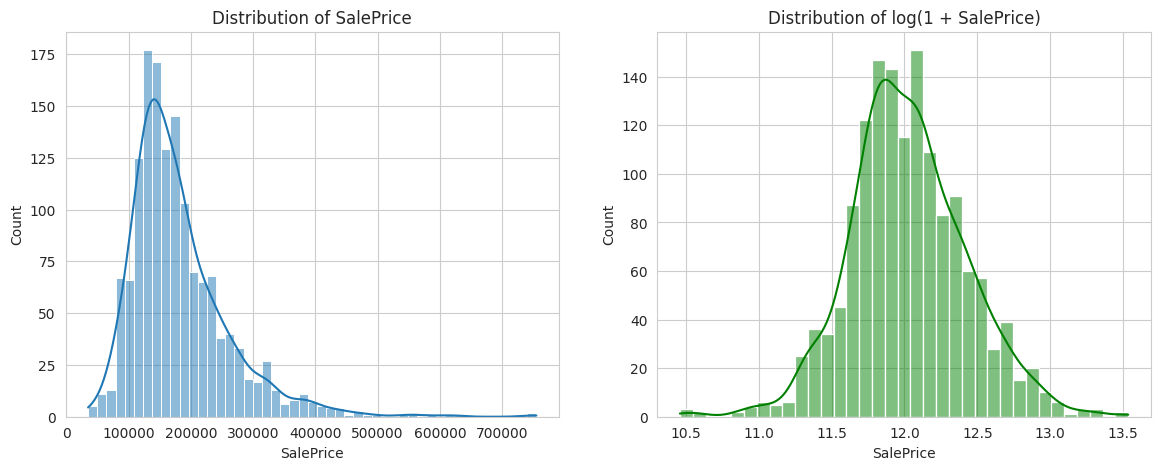

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(train_clean['SalePrice'], kde=True, ax=axes[0])
axes[0].set_title('Distribution of SalePrice')

sns.histplot(np.log1p(train_clean['SalePrice']), kde=True, ax=axes[1], color='green')
axes[1].set_title('Distribution of log(1 + SalePrice)')

plt.show()

**Observation:** `SalePrice` is **right-skewed** (skewness of about 1.88). Most houses are cheap and a few very expensive ones stretch the tail.
After applying `log1p` the distribution is close to a bell curve.

**Why this matters:** regression models work best when the target is roughly symmetric, and the Kaggle metric is measured on the log scale. So we will **train on `log1p(SalePrice)`** and convert predictions back with `expm1`.

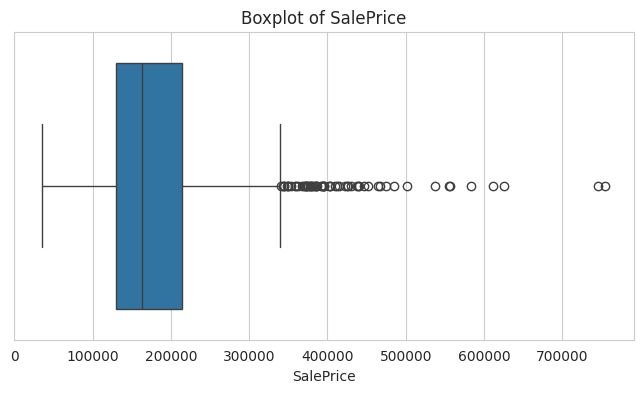

In [17]:
plt.figure(figsize=(8, 4))
sns.boxplot(x=train_clean['SalePrice'])
plt.title('Boxplot of SalePrice')
plt.show()

### 5.2 Numerical features and their correlation with `SalePrice`

In [18]:
numeric_features = (
    train_clean.select_dtypes(include=np.number)
    .drop(columns=['Id', 'SalePrice'])
    .columns
)

correlation = (
    train_clean[numeric_features.tolist() + ['SalePrice']]
    .corr()['SalePrice']
    .sort_values(ascending=False)
)
print(correlation)

SalePrice        1.000000
OverallQual      0.790982
GrLivArea        0.708624
GarageCars       0.640409
GarageArea       0.623431
TotalBsmtSF      0.613581
1stFlrSF         0.605852
FullBath         0.560664
TotRmsAbvGrd     0.533723
YearBuilt        0.522897
GarageYrBlt      0.508043
YearRemodAdd     0.507101
MasVnrArea       0.472614
Fireplaces       0.466929
BsmtFinSF1       0.386420
LotFrontage      0.349876
WoodDeckSF       0.324413
2ndFlrSF         0.319334
OpenPorchSF      0.315856
HalfBath         0.284108
LotArea          0.263843
BsmtFullBath     0.227122
BsmtUnfSF        0.214479
BedroomAbvGr     0.168213
ScreenPorch      0.111447
PoolArea         0.092404
MoSold           0.046432
3SsnPorch        0.044584
BsmtFinSF2      -0.011378
BsmtHalfBath    -0.016844
MiscVal         -0.021190
LowQualFinSF    -0.025606
YrSold          -0.028923
OverallCond     -0.077856
MSSubClass      -0.084284
EnclosedPorch   -0.128578
KitchenAbvGr    -0.135907
Name: SalePrice, dtype: float64


**Observation:** `OverallQual` (about 0.79) and `GrLivArea` (about 0.71) are the strongest drivers. Garage size, basement size and first-floor area follow.
Features such as `MoSold`, `YrSold`, `MiscVal` and `LowQualFinSF` have almost no linear relationship with price.

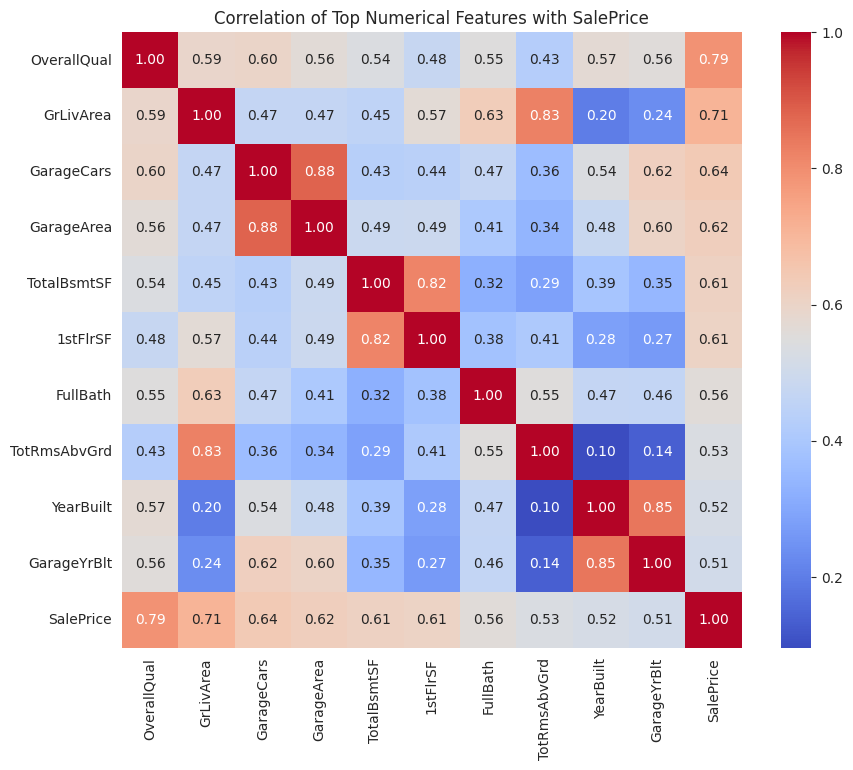

In [19]:
top_numeric_features = correlation.drop('SalePrice').head(10)

plt.figure(figsize=(10, 8))
sns.heatmap(
    train_clean[top_numeric_features.index.tolist() + ['SalePrice']].corr(),
    annot=True, fmt='.2f', cmap='coolwarm'
)
plt.title('Correlation of Top Numerical Features with SalePrice')
plt.show()

**Observation:** several top features are strongly correlated **with each other**, for example `GarageCars` and `GarageArea`, or `GrLivArea` and `TotRmsAbvGrd`. This is **multicollinearity**. It is harmless for tree models but can make plain Linear Regression unstable. We will see that effect later.

### 5.3 Key relationships

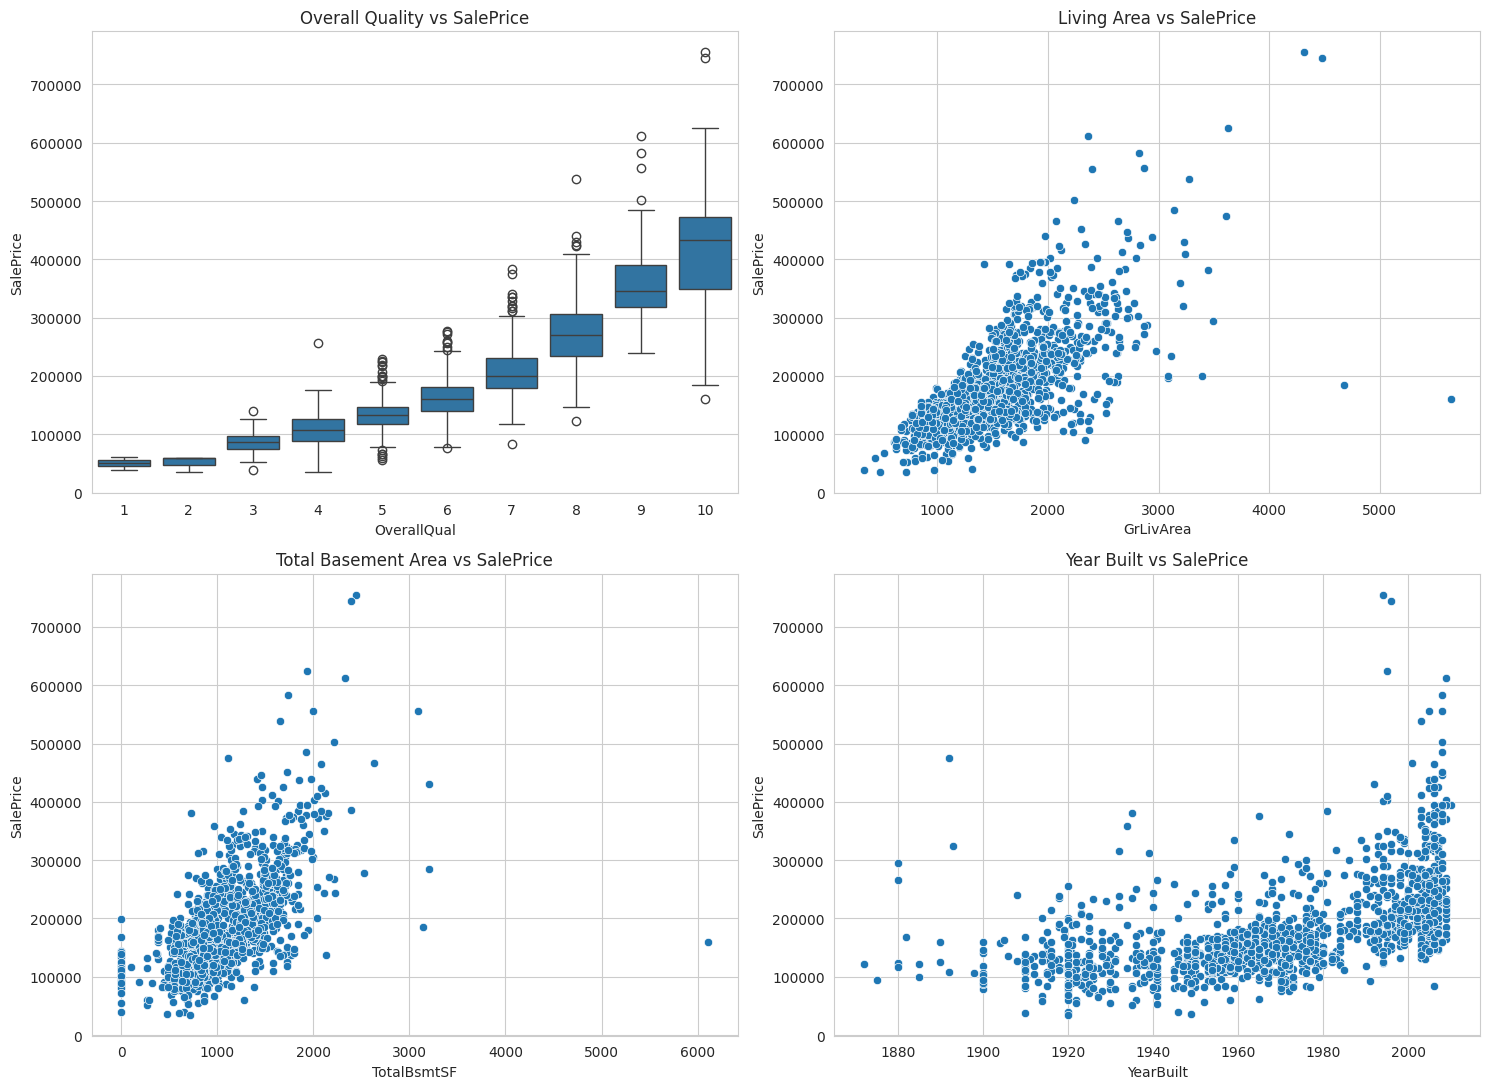

In [20]:
fig, axes = plt.subplots(2, 2, figsize=(15, 11))

sns.boxplot(data=train_clean, x='OverallQual', y='SalePrice', ax=axes[0, 0])
axes[0, 0].set_title('Overall Quality vs SalePrice')

sns.scatterplot(data=train_clean, x='GrLivArea', y='SalePrice', ax=axes[0, 1])
axes[0, 1].set_title('Living Area vs SalePrice')

sns.scatterplot(data=train_clean, x='TotalBsmtSF', y='SalePrice', ax=axes[1, 0])
axes[1, 0].set_title('Total Basement Area vs SalePrice')

sns.scatterplot(data=train_clean, x='YearBuilt', y='SalePrice', ax=axes[1, 1])
axes[1, 1].set_title('Year Built vs SalePrice')

plt.tight_layout()
plt.show()

**Observations**
- **OverallQual:** price rises steadily with quality, and the jump at the top levels (9 and 10) is large.
- **GrLivArea:** a clear upward trend, but **two houses on the far right** have a huge living area and a low price. They do not follow the pattern (see the outlier section).
- **TotalBsmtSF:** positive relationship; one very large basement stands out.
- **YearBuilt:** newer houses tend to cost more.

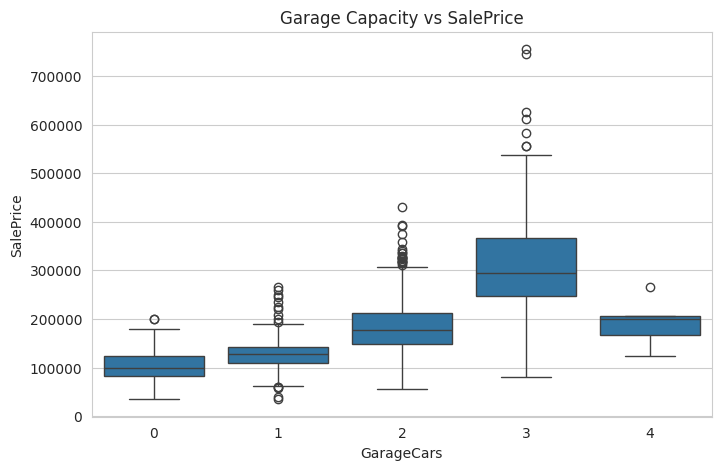

In [21]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=train_clean, x='GarageCars', y='SalePrice')
plt.title('Garage Capacity vs SalePrice')
plt.show()

**Observation:** price rises from 0 to 2 cars, then flattens at 3. A 4-car garage does **not** mean a more expensive house. This is a hint that the relationship is not purely linear.

### 5.4 Categorical features

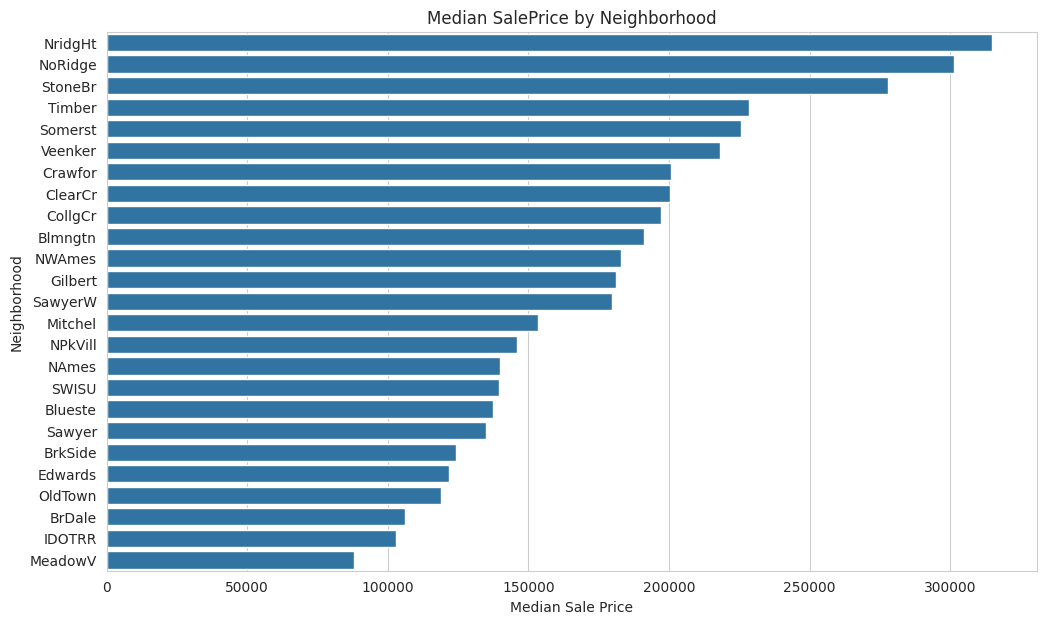

In [22]:
neighborhood_price = (
    train_clean.groupby('Neighborhood')['SalePrice']
    .median()
    .sort_values(ascending=False)
)

plt.figure(figsize=(12, 7))
sns.barplot(x=neighborhood_price.values, y=neighborhood_price.index)
plt.title('Median SalePrice by Neighborhood')
plt.xlabel('Median Sale Price')
plt.show()

**Observation:** location matters a lot. The median price in the top neighbourhoods (`NridgHt`, `NoRidge`, `StoneBr`) is more than **3 times** that of the cheapest (`MeadowV`, `IDOTRR`). `Neighborhood` will be an important feature.

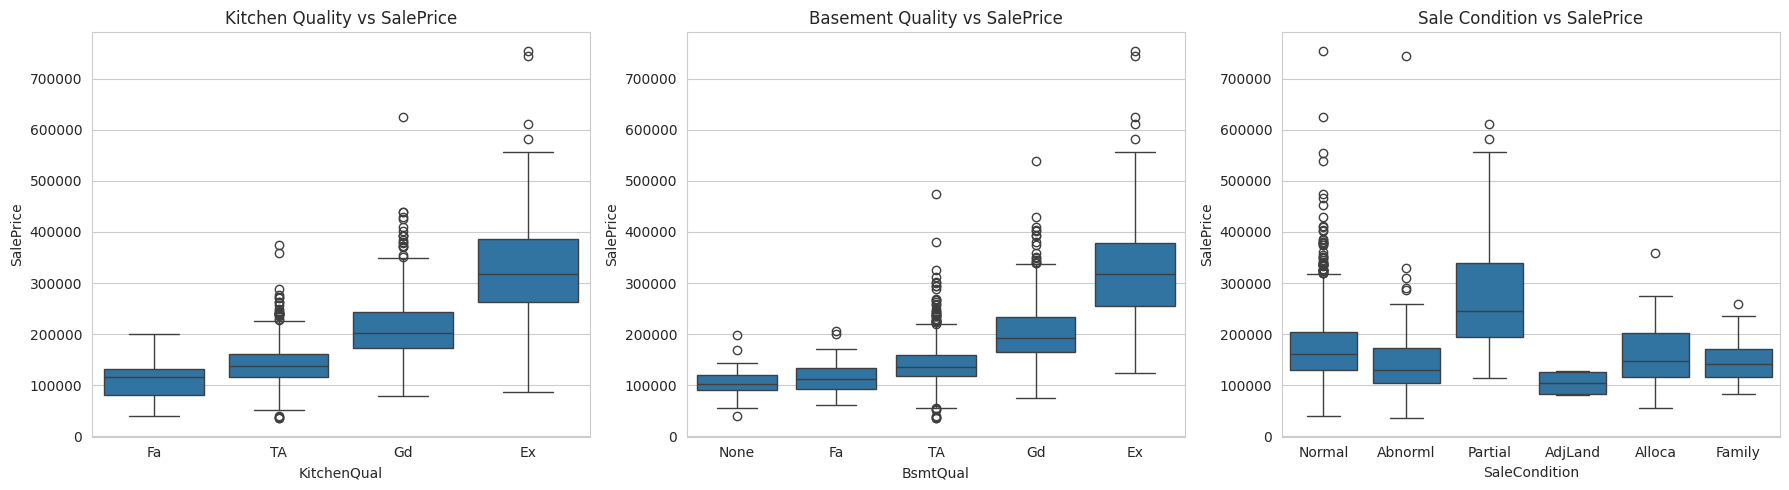

In [23]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.boxplot(data=train_clean, x='KitchenQual', y='SalePrice', order=['Fa', 'TA', 'Gd', 'Ex'], ax=axes[0])
axes[0].set_title('Kitchen Quality vs SalePrice')

sns.boxplot(data=train_clean, x='BsmtQual', y='SalePrice', order=['None', 'Fa', 'TA', 'Gd', 'Ex'], ax=axes[1])
axes[1].set_title('Basement Quality vs SalePrice')

sns.boxplot(data=train_clean, x='SaleCondition', y='SalePrice', ax=axes[2])
axes[2].set_title('Sale Condition vs SalePrice')

plt.tight_layout()
plt.show()

**Observations**
- **KitchenQual and BsmtQual** have a clear natural order (Fair, Typical, Good, Excellent) and price rises with every step. Because they are *ordered*, we will encode them as numbers (1 to 5) in the preprocessing step instead of one-hot encoding them.
- **SaleCondition:** `Partial` sales (new homes sold before completion) have the highest prices.

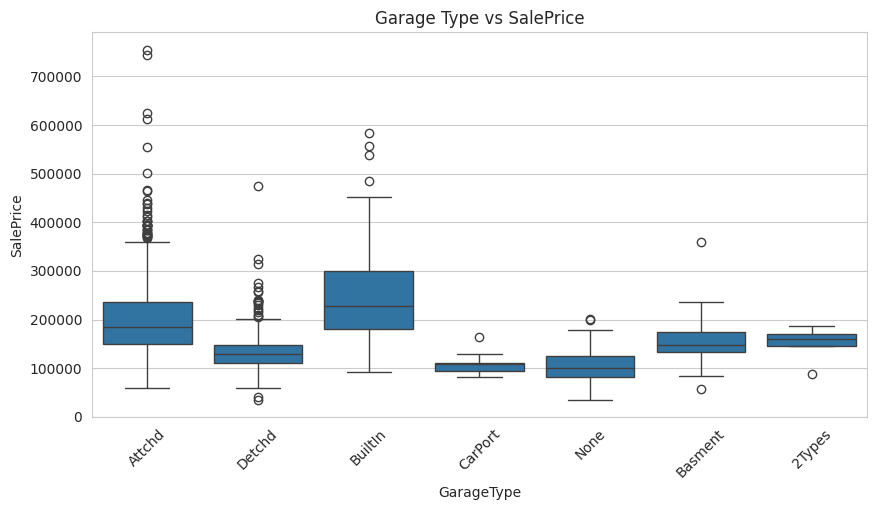

In [24]:
plt.figure(figsize=(10, 5))
sns.boxplot(data=train_clean, x='GarageType', y='SalePrice')
plt.title('Garage Type vs SalePrice')
plt.xticks(rotation=45)
plt.show()

**Observation:** attached and built-in garages are linked to higher prices than detached or no garage.

### 5.5 Outlier analysis

We use the **IQR rule** to flag unusual values: anything below `Q1 - 1.5*IQR` or above `Q3 + 1.5*IQR`.

In [25]:
def iqr_bounds(series):
    q1, q3 = series.quantile(0.25), series.quantile(0.75)
    iqr = q3 - q1
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr


low, high = iqr_bounds(train_clean['GrLivArea'])
print("GrLivArea bounds:", low, high)

grlivarea_outliers = train_clean[(train_clean['GrLivArea'] < low) | (train_clean['GrLivArea'] > high)]
print("Potential GrLivArea outliers:", len(grlivarea_outliers))

low_p, high_p = iqr_bounds(train_clean['SalePrice'])
price_outliers = train_clean[(train_clean['SalePrice'] < low_p) | (train_clean['SalePrice'] > high_p)]
print("Potential SalePrice outliers:", len(price_outliers))

GrLivArea bounds: 158.625 2747.625
Potential GrLivArea outliers: 31
Potential SalePrice outliers: 61


The IQR rule flags **31** houses by living area and **61** by price. **That does not mean we should delete them.**

Statistical outliers are not always errors. Most of these are simply large, high-quality houses in expensive neighbourhoods (`OverallQual` 9 or 10 in `NoRidge`, `NridgHt`) that sold for high prices. They are legitimate, and removing them would hurt the model.

The real anomalies are houses whose **price does not match their size**. Let's look at the scatter plot with the suspicious area highlighted.

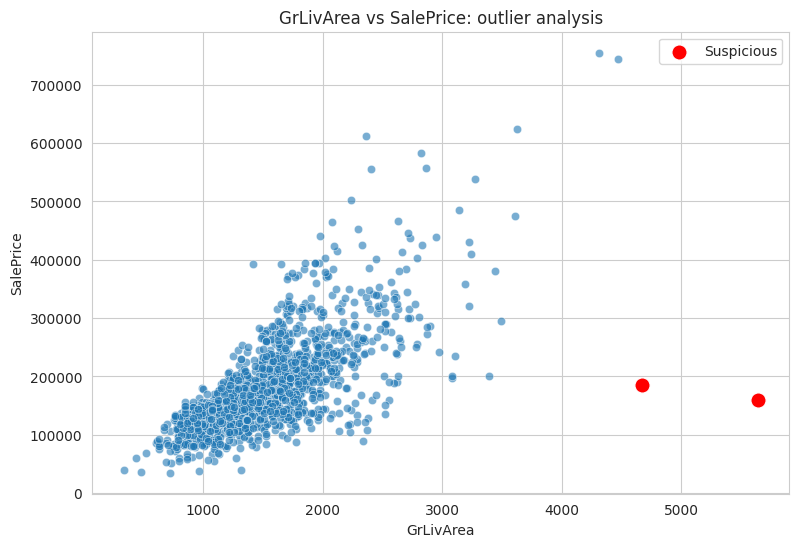

,Id,GrLivArea,OverallQual,Neighborhood,SaleCondition,SalePrice
523,524,4676,10,Edwards,Partial,184750
1298,1299,5642,10,Edwards,Partial,160000


In [26]:
suspicious = (train_clean['GrLivArea'] > 4000) & (train_clean['SalePrice'] < 300000)

plt.figure(figsize=(9, 6))
sns.scatterplot(data=train_clean, x='GrLivArea', y='SalePrice', alpha=0.6)
sns.scatterplot(data=train_clean[suspicious], x='GrLivArea', y='SalePrice', color='red', s=120, label='Suspicious')
plt.title('GrLivArea vs SalePrice: outlier analysis')
plt.show()

train_clean.loc[suspicious, ['Id', 'GrLivArea', 'OverallQual', 'Neighborhood', 'SaleCondition', 'SalePrice']]

**Observation:** two houses (more than 4,000 sq ft, with prices of only about \$160k to \$185k) break the trend. Both are **partial sales** in `Edwards`. They were sold under unusual circumstances, so the price does not reflect the house. The two houses above 4,000 sq ft that sold for \$700k+ follow the trend and are kept.

The dataset's author recommends removing exactly these points. Since they would pull the regression line down, we **remove only these two rows from train**. We never remove rows from test.

In [27]:
before = len(train_clean)
train_clean = train_clean[~suspicious].reset_index(drop=True)
print(f"Rows removed: {before - len(train_clean)}")
print("New train shape:", train_clean.shape)

Rows removed: 2
New train shape: (1458, 81)


📖 If you want to know why each step is here, read the companion post on Medium: [Predicting House Prices: What My Mistakes Taught Me](https://medium.com/@parulrajput27/predicting-house-prices-what-my-mistakes-taught-me-aa9ef42b549b?source=friends_link&sk=a043e1d08f041a751085bc3c8a5975f2)

## 6. Feature Engineering

New features that capture information the raw columns hide. Each is checked against `SalePrice`.

| Feature | Idea |
|---|---|
| `TotalSF` | total living space = basement + 1st floor + 2nd floor |
| `TotalBathrooms` | full baths + 0.5 x half baths, including the basement |
| `HouseAge` | age of the house when sold |
| `RemodAge` | years since the last remodel when sold |
| `TotalPorchSF` | total porch and deck area |
| `HasGarage`, `HasBasement`, `Has2ndFloor`, `HasFireplace`, `HasPool` | simple yes/no flags |

The flags help especially because absent features get a zero in area columns, and a flag tells the model *explicitly* that the feature does not exist.

In [28]:
def add_features(df):
    df = df.copy()

    df['TotalSF'] = df['TotalBsmtSF'] + df['1stFlrSF'] + df['2ndFlrSF']

    df['TotalBathrooms'] = (
        df['FullBath'] + 0.5 * df['HalfBath']
        + df['BsmtFullBath'] + 0.5 * df['BsmtHalfBath']
    )

    # clip(lower=0): a house sold before its build/remodel year would give a negative age
    df['HouseAge'] = (df['YrSold'] - df['YearBuilt']).clip(lower=0)
    df['RemodAge'] = (df['YrSold'] - df['YearRemodAdd']).clip(lower=0)

    df['TotalPorchSF'] = (
        df['WoodDeckSF'] + df['OpenPorchSF'] + df['EnclosedPorch']
        + df['3SsnPorch'] + df['ScreenPorch']
    )

    df['HasGarage'] = (df['GarageType'] != 'None').astype(int)
    df['HasBasement'] = (df['TotalBsmtSF'] > 0).astype(int)
    df['Has2ndFloor'] = (df['2ndFlrSF'] > 0).astype(int)
    df['HasFireplace'] = (df['Fireplaces'] > 0).astype(int)
    df['HasPool'] = (df['PoolArea'] > 0).astype(int)
    return df


train_fe = add_features(train_clean)
test_fe = add_features(test_clean)

engineered_features = [
    'TotalSF', 'TotalBathrooms', 'HouseAge', 'RemodAge', 'TotalPorchSF',
    'HasGarage', 'HasBasement', 'Has2ndFloor', 'HasFireplace', 'HasPool'
]

train_fe[engineered_features + ['SalePrice']].corr()['SalePrice'].sort_values(ascending=False)

SalePrice         1.000000
TotalSF           0.832877
TotalBathrooms    0.635896
HasFireplace      0.472350
TotalPorchSF      0.392897
HasGarage         0.236883
HasBasement       0.152860
Has2ndFloor       0.137953
HasPool           0.103995
RemodAge         -0.509706
HouseAge         -0.524067
Name: SalePrice, dtype: float64

**Observations**
- `TotalSF` has a correlation of about **0.78+** with price. It beats every original area column except `OverallQual`, so it will be one of the most useful features.
- `TotalBathrooms` is about 0.63, so more bathrooms usually means a more expensive house.
- `HouseAge` and `RemodAge` are **negative** (about -0.52 and -0.51): older and less recently remodelled houses sell for less.
- `TotalPorchSF` is a weaker positive signal (about 0.39).

### 6.1 Encode ordered quality columns as numbers

Columns like `ExterQual`, `KitchenQual` or `BsmtQual` use the scale Excellent, Good, Typical, Fair, Poor. This order carries information, and one-hot encoding throws it away and creates many extra columns.

We map them to numbers: **None = 0, Poor = 1, Fair = 2, Typical = 3, Good = 4, Excellent = 5**.

In [29]:
quality_map = {'None': 0, 'Po': 1, 'Fa': 2, 'TA': 3, 'Gd': 4, 'Ex': 5}

quality_cols = [
    'ExterQual', 'ExterCond', 'BsmtQual', 'BsmtCond', 'HeatingQC',
    'KitchenQual', 'FireplaceQu', 'GarageQual', 'GarageCond', 'PoolQC'
]


def encode_ordinals(df):
    df = df.copy()
    for col in quality_cols:
        df[col] = df[col].map(quality_map)
    # MSSubClass is a numeric CODE for a dwelling type, so treat it as a category
    df['MSSubClass'] = df['MSSubClass'].astype(str)
    return df


train_fe = encode_ordinals(train_fe)
test_fe = encode_ordinals(test_fe)

print(train_fe[['ExterQual', 'KitchenQual', 'BsmtQual']].head())

   ExterQual  KitchenQual  BsmtQual
0          4            4         4
1          3            3         4
2          4            4         4
3          3            4         3
4          4            4         4


## 7. Preprocessing

### 7.1 Separate features and target

- `X` = all features, `y_log` = `log1p(SalePrice)`.
- `Id` is just a row label with no meaning for price, so we drop it. (We keep `test['Id']` to build the submission file later.)

In [30]:
X = train_fe.drop(columns=['SalePrice', 'Id'])
y_log = np.log1p(train_fe['SalePrice'])
y_raw = train_fe['SalePrice']

X_test = test_fe.drop(columns=['Id'])

print("X shape:", X.shape)
print("y shape:", y_log.shape)
print("X_test shape:", X_test.shape)

X shape: (1458, 89)
y shape: (1458,)
X_test shape: (1459, 89)


### 7.2 Reduce skew in numeric features

Many area columns (`LotArea`, `GrLivArea`, `TotalSF`, `MiscVal` and so on) are heavily right-skewed, just like the target. We apply `log1p` to numeric features with |skew| > 0.75. The skew is measured **on train only**, and the same list of columns is transformed in both train and test. Yes/no flags are skipped.

In [31]:
numeric_features = X.select_dtypes(include=['int64', 'float64']).columns.tolist()
categorical_features = X.select_dtypes(include=['object']).columns.tolist()

skewness = X[numeric_features].skew().abs()
skewed_cols = [
    c for c in skewness[skewness > 0.75].index
    if X[c].nunique() > 2 and X[c].min() >= 0
]

print(f"{len(skewed_cols)} skewed columns will be log-transformed:")
print(skewed_cols)

X[skewed_cols] = np.log1p(X[skewed_cols])
X_test[skewed_cols] = np.log1p(X_test[skewed_cols])

28 skewed columns will be log-transformed:
['LotFrontage', 'LotArea', 'MasVnrArea', 'ExterQual', 'ExterCond', 'BsmtQual', 'BsmtCond', 'BsmtFinSF1', 'BsmtFinSF2', 'BsmtUnfSF', '1stFlrSF', '2ndFlrSF', 'LowQualFinSF', 'GrLivArea', 'BsmtHalfBath', 'KitchenAbvGr', 'GarageQual', 'GarageCond', 'WoodDeckSF', 'OpenPorchSF', 'EnclosedPorch', '3SsnPorch', 'ScreenPorch', 'PoolArea', 'PoolQC', 'MiscVal', 'TotalSF', 'TotalPorchSF']


In [32]:
print("Numerical features:", len(numeric_features))
print("Categorical features:", len(categorical_features))

Numerical features: 55
Categorical features: 34


### 7.3 Preprocessing pipeline

| Feature type | Steps |
|---|---|
| Numerical | fill gaps with the **median** then **StandardScaler** (mean 0, std 1) |
| Categorical | fill gaps with the **most frequent** value then **OneHotEncoder** (`handle_unknown='ignore'` so unseen categories in test don't crash the model) |

We put the imputer in the pipeline so that medians and modes are always learned from the **training data only**.

In [33]:
numeric_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer([
    ('num', numeric_pipe, numeric_features),
    ('cat', categorical_pipe, categorical_features)
])

print("Preprocessing pipeline created.")

Preprocessing pipeline created.


### 7.4 Why we do not pre-transform the data by hand

In an earlier version of this project, we called `preprocessor.fit_transform(X)` on the **full** data and got **321 features**, but the validation matrix from the earlier fit on the 80% split had **319**. The model then crashed with `X has 319 features, but the model is expecting 321`.

**Why:** `OneHotEncoder` creates one column per category *it sees while fitting*. Fitting on a different subset of rows finds a different set of categories, so the columns changed. A model trained on one column layout can't read another.

**Fix:** put the preprocessor and the model **in one `Pipeline`**. The pipeline refits the preprocessor and the model together on whatever data it gets, and applies the same fitted preprocessor when predicting. Mismatches become impossible, and cross-validation is automatically leakage-free.

## 8. Model Building

We compare four model types, scored on **log RMSE** (the Kaggle metric; lower is better).

| Model | Why |
|---|---|
| Linear Regression | simple baseline |
| Ridge | linear model with L2 penalty, which handles multicollinearity |
| Lasso | linear model with L1 penalty, which also drops weak features |
| Random Forest | many independent decision trees, which captures non-linear effects |
| Gradient Boosting | trees built one after another, each fixing the previous errors |

### Cross-validation instead of one split

Using a single 80/20 split gives a result that depends on which rows landed in validation. **5-fold cross-validation** trains and tests 5 times on different parts of the data and averages the result, so the score is far more reliable.

In [34]:
kf = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)


def cv_log_rmse(model):
    pipe = Pipeline([('prep', preprocessor), ('model', model)])
    scores = -cross_val_score(
        pipe, X, y_log,
        scoring='neg_root_mean_squared_error',
        cv=kf, n_jobs=-1
    )
    return scores.mean(), scores.std()


models = {
    'Linear Regression': LinearRegression(),
    'Ridge (alpha=10)': Ridge(alpha=10),
    'Lasso (alpha=0.0005)': Lasso(alpha=0.0005, max_iter=20000),
    'Random Forest': RandomForestRegressor(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1),
    'Gradient Boosting': GradientBoostingRegressor(
        n_estimators=300, learning_rate=0.05, max_depth=3, random_state=RANDOM_STATE
    ),
}

rows = []
for name, model in models.items():
    mean, std = cv_log_rmse(model)
    rows.append({'Model': name, 'CV Log RMSE': mean, 'Std': std})
    print(f"{name:25s} {mean:.5f} (+/- {std:.5f})")

results = pd.DataFrame(rows).sort_values('CV Log RMSE').reset_index(drop=True)
results

Linear Regression         0.22692 (+/- 0.17990)
Ridge (alpha=10)          0.11364 (+/- 0.00719)
Lasso (alpha=0.0005)      0.11213 (+/- 0.00640)
Random Forest             0.13560 (+/- 0.00602)
Gradient Boosting         0.12196 (+/- 0.00607)


,Model,CV Log RMSE,Std
0,Lasso (alpha=0.0005),0.112128,0.006401
1,Ridge (alpha=10),0.113640,0.007189
2,Gradient Boosting,0.121963,0.006066
3,Random Forest,0.135600,0.006021
4,Linear Regression,0.226924,0.179897


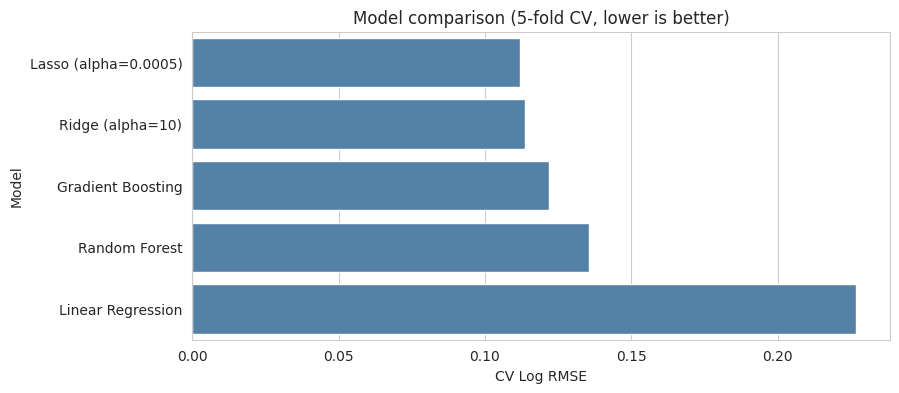

In [35]:
plt.figure(figsize=(9, 4))
sns.barplot(data=results, x='CV Log RMSE', y='Model', color='steelblue')
plt.title('Model comparison (5-fold CV, lower is better)')
plt.show()

**How to read this:**
- Write your own numbers here after running. Expect Ridge, Lasso and Gradient Boosting to be close to each other, and Random Forest to be a bit behind.
- Linear models improved a lot compared with our first version. Before, plain Linear Regression had a **dollar RMSE of about 70,000** because of **outliers** (the two giant cheap houses pulled the line down) and **multicollinearity** (for example `TotalSF` is the sum of other columns). Removing the outliers and using the log target and regularisation fixed most of that.
- **Regularised linear models (Ridge, Lasso)** are strong here because after log transforms, the relationships with price are close to linear.

### 8.1 Why train on the log of the price?

Let's prove it with a fair test on one hold-out split. We train the same Gradient Boosting model twice, once on raw `SalePrice` and once on `log1p(SalePrice)`, and score **both on the log scale**, which is the metric Kaggle uses.

In [36]:
X_tr, X_va, ylog_tr, ylog_va, yraw_tr, yraw_va = train_test_split(
    X, y_log, y_raw, test_size=0.2, random_state=RANDOM_STATE
)

gb_params = dict(n_estimators=300, learning_rate=0.05, max_depth=3, random_state=RANDOM_STATE)

pipe_raw = Pipeline([('prep', preprocessor), ('model', GradientBoostingRegressor(**gb_params))])
pipe_raw.fit(X_tr, yraw_tr)
pred_raw = pipe_raw.predict(X_va)

pipe_log = Pipeline([('prep', preprocessor), ('model', GradientBoostingRegressor(**gb_params))])
pipe_log.fit(X_tr, ylog_tr)
pred_log = pipe_log.predict(X_va)


def rmse(a, b):
    return np.sqrt(mean_squared_error(a, b))


print("Raw target:  log RMSE =", rmse(ylog_va, np.log1p(np.clip(pred_raw, 1, None))))
print("Log target:  log RMSE =", rmse(ylog_va, pred_log))
print()
print("Raw target:  dollar RMSE =", rmse(yraw_va, pred_raw))
print("Log target:  dollar RMSE =", rmse(yraw_va, np.expm1(pred_log)))

Raw target:  log RMSE = 0.12176395079311965
Log target:  log RMSE = 0.1183507201708555

Raw target:  dollar RMSE = 20266.597028193242
Log target:  dollar RMSE = 19462.5138599955


**Important point about metrics (this confused us earlier):** in the first version, the log-target model had a **worse dollar RMSE** (about 28.5k vs 25.9k) than the raw-target model, even though its log RMSE was good. That is not a contradiction.

- **Dollar RMSE** is dominated by the few very expensive houses, because an error of \$50k on a \$500k house counts as much as 5 errors of \$10k on cheap houses.
- **Log RMSE** measures *percentage-style* error, which treats a 10% mistake the same on a cheap or an expensive house.

Kaggle scores log RMSE, so that is the number to optimise. The dollar RMSE is still useful for a business-friendly sentence such as "on average we are off by about \$X".

## 9. Hyperparameter Tuning

Gradient Boosting has settings that control how it learns:

| Parameter | Meaning |
|---|---|
| `n_estimators` | number of trees |
| `learning_rate` | how much each tree contributes (small = slow and careful) |
| `max_depth` | how complex each tree can be |
| `subsample` | fraction of rows used for each tree (below 1 adds randomness, which reduces overfitting) |

In our first attempt, the best values (`max_depth=4`, `n_estimators=500`) were at the **edge of the grid**, which means better values might lie beyond it. So this time the grid is wider. Because the preprocessor is inside the pipeline, parameter names get the prefix `model__`.

In [37]:
gb_pipe = Pipeline([
    ('prep', preprocessor),
    ('model', GradientBoostingRegressor(random_state=RANDOM_STATE))
])

param_grid = {
    'model__n_estimators': [300, 500, 800],
    'model__learning_rate': [0.02, 0.05],
    'model__max_depth': [3, 4, 5],
    'model__subsample': [0.7, 1.0],
}

gb_grid = GridSearchCV(
    gb_pipe, param_grid,
    scoring='neg_root_mean_squared_error',
    cv=kf, n_jobs=-1, verbose=1
)
gb_grid.fit(X, y_log)

print("Best parameters:")
print(gb_grid.best_params_)
print("\nBest CV Log RMSE:", -gb_grid.best_score_)

Fitting 5 folds for each of 36 candidates, totalling 180 fits
Best parameters:
{'model__learning_rate': 0.02, 'model__max_depth': 4, 'model__n_estimators': 800, 'model__subsample': 0.7}

Best CV Log RMSE: 0.11581411934946169


**Note:** this search tries 36 combinations x 5 folds = 180 fits, so it may take a few minutes. If you want a faster version, reduce the lists.

**How to read the result:** compare the tuned score with the untuned Gradient Boosting score from Section 8. Tuning normally gives a **small** gain. If the gain is tiny, the default model was already good, and that is also a valid finding.

### 9.1 Tune Ridge too

Ridge's penalty strength (`alpha`) matters a lot. A quick search keeps this fair for the linear side.

In [38]:
ridge_pipe = Pipeline([('prep', preprocessor), ('model', Ridge())])

ridge_grid = GridSearchCV(
    ridge_pipe,
    {'model__alpha': [1, 3, 5, 10, 15, 20, 30, 50]},
    scoring='neg_root_mean_squared_error',
    cv=kf, n_jobs=-1
)
ridge_grid.fit(X, y_log)

print("Best Ridge alpha:", ridge_grid.best_params_)
print("Best Ridge CV Log RMSE:", -ridge_grid.best_score_)

Best Ridge alpha: {'model__alpha': 15}
Best Ridge CV Log RMSE: 0.11344352107930786


## 10. Blending and Final Validation

### 10.1 Blend Ridge and Gradient Boosting

Ridge and Gradient Boosting make *different kinds* of mistakes (one is linear, the other is tree-based). Averaging them often beats either model alone. We get **out-of-fold predictions** (each house is predicted by a model that never saw it), then find the best mixing weight.

In [39]:
best_ridge = ridge_grid.best_estimator_
best_gb = gb_grid.best_estimator_

oof_ridge = cross_val_predict(best_ridge, X, y_log, cv=kf, n_jobs=-1)
oof_gb = cross_val_predict(best_gb, X, y_log, cv=kf, n_jobs=-1)

weights = np.linspace(0, 1, 11)
blend_scores = [rmse(y_log, w * oof_gb + (1 - w) * oof_ridge) for w in weights]

for w, s in zip(weights, blend_scores):
    print(f"GB weight {w:.1f} / Ridge weight {1 - w:.1f}:  log RMSE = {s:.5f}")

best_w = weights[int(np.argmin(blend_scores))]
print(f"\nBest GB weight: {best_w:.1f}")
print("Ridge only :", rmse(y_log, oof_ridge))
print("GB only    :", rmse(y_log, oof_gb))
print("Blend      :", min(blend_scores))

GB weight 0.0 / Ridge weight 1.0:  log RMSE = 0.11368
GB weight 0.1 / Ridge weight 0.9:  log RMSE = 0.11224
GB weight 0.2 / Ridge weight 0.8:  log RMSE = 0.11117
GB weight 0.3 / Ridge weight 0.7:  log RMSE = 0.11046
GB weight 0.4 / Ridge weight 0.6:  log RMSE = 0.11013
GB weight 0.5 / Ridge weight 0.5:  log RMSE = 0.11017
GB weight 0.6 / Ridge weight 0.4:  log RMSE = 0.11059
GB weight 0.7 / Ridge weight 0.3:  log RMSE = 0.11138
GB weight 0.8 / Ridge weight 0.2:  log RMSE = 0.11253
GB weight 0.9 / Ridge weight 0.1:  log RMSE = 0.11404
GB weight 1.0 / Ridge weight 0.0:  log RMSE = 0.11589

Best GB weight: 0.4
Ridge only : 0.11367540694920755
GB only    : 0.11588913004244544
Blend      : 0.11012547253692645


**Observation:** if the blend score is lower than both single models, blending helped. The best weight is the one with the lowest error in the table above, and it will be used for the final submission.

### 10.2 Hold-out check on the original price scale

As a final sanity check, we train the blend on 80% of the data, then predict the 20% it has never seen, and convert back to dollars.

In [40]:
from sklearn.base import clone

ridge_h = clone(best_ridge).fit(X_tr, ylog_tr)
gb_h = clone(best_gb).fit(X_tr, ylog_tr)

blend_log_pred = best_w * gb_h.predict(X_va) + (1 - best_w) * ridge_h.predict(X_va)
blend_price_pred = np.expm1(blend_log_pred)

print("Hold-out Log RMSE      :", rmse(ylog_va, blend_log_pred))
print("Hold-out Dollar RMSE   :", rmse(yraw_va, blend_price_pred))
print("Hold-out mean abs error: $", round(np.mean(np.abs(yraw_va - blend_price_pred))))

Hold-out Log RMSE      : 0.11306170341704051
Hold-out Dollar RMSE   : 18203.531991615975
Hold-out mean abs error: $ 13236


In [41]:
comparison = pd.DataFrame({
    'Actual SalePrice': yraw_va.values,
    'Predicted SalePrice': blend_price_pred.round(0),
})
comparison['Error'] = comparison['Predicted SalePrice'] - comparison['Actual SalePrice']
comparison['Error %'] = (comparison['Error'] / comparison['Actual SalePrice'] * 100).round(1)
comparison.head(10)

,Actual SalePrice,Predicted SalePrice,Error,Error %
0,190000,227554.0,37554.0,19.8
1,100000,97738.0,-2262.0,-2.3
2,115000,103473.0,-11527.0,-10.0
3,159000,162622.0,3622.0,2.3
4,315500,318423.0,2923.0,0.9
5,137500,145417.0,7917.0,5.8
6,311500,236845.0,-74655.0,-24.0
7,310000,329516.0,19516.0,6.3
8,281000,283181.0,2181.0,0.8
9,135500,143916.0,8416.0,6.2


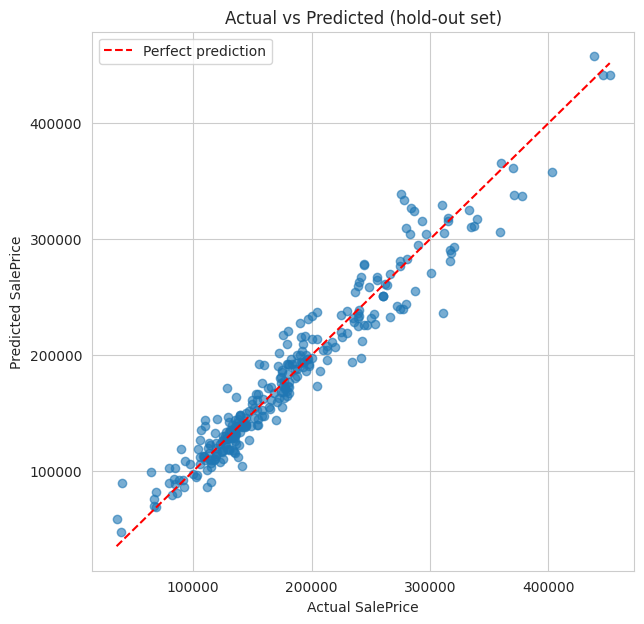

In [42]:
plt.figure(figsize=(7, 7))
plt.scatter(yraw_va, blend_price_pred, alpha=0.6)
lims = [yraw_va.min(), yraw_va.max()]
plt.plot(lims, lims, 'r--', label='Perfect prediction')
plt.xlabel('Actual SalePrice')
plt.ylabel('Predicted SalePrice')
plt.title('Actual vs Predicted (hold-out set)')
plt.legend()
plt.show()

**How to read the plot:** points close to the red dashed line are accurate predictions. Expect a tight cluster for the typical houses (\$100k to \$300k) and more scatter for the most expensive ones, because there are very few of them to learn from.

### 10.3 Which features does the model use most?

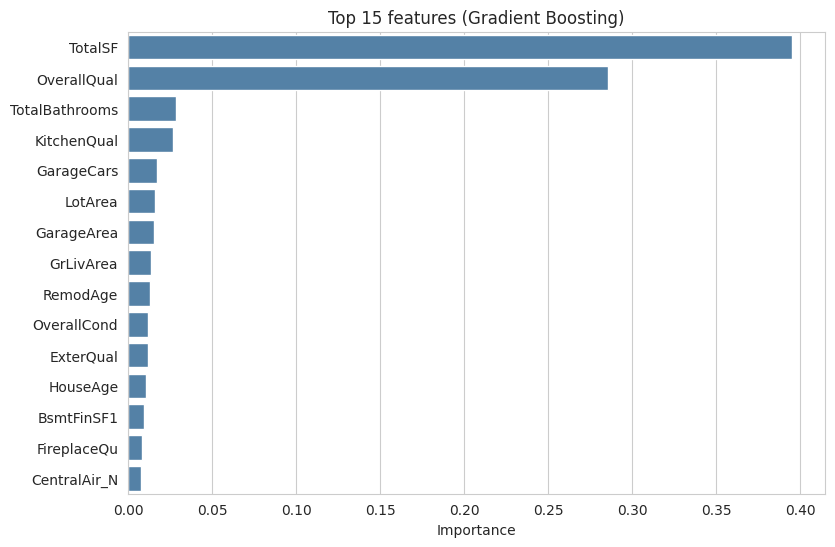

In [43]:
gb_h_prep = gb_h.named_steps['prep']
feature_names = gb_h_prep.get_feature_names_out()
importances = pd.Series(
    gb_h.named_steps['model'].feature_importances_, index=feature_names
).sort_values(ascending=False).head(15)

plt.figure(figsize=(9, 6))
sns.barplot(x=importances.values, y=[n.split('__')[1] for n in importances.index], color='steelblue')
plt.title('Top 15 features (Gradient Boosting)')
plt.xlabel('Importance')
plt.show()

**Observation:** the model's top features should match what the EDA told us: `OverallQual`, `TotalSF` / `GrLivArea`, neighbourhood, garage size, and house age. That agreement is a good sign that the model has learned real patterns rather than noise.

## 11. Final Model and Submission

Now we retrain both models on **all** training data (more data means a better model), then predict the test set.

Because the preprocessor lives inside each pipeline, the test set is transformed with exactly the same fitted encoder and scaler, so no feature mismatch is possible.

In [44]:
final_ridge = clone(best_ridge).fit(X, y_log)
final_gb = clone(best_gb).fit(X, y_log)

test_pred_log = best_w * final_gb.predict(X_test) + (1 - best_w) * final_ridge.predict(X_test)

# Convert back from log scale to dollars
test_pred = np.expm1(test_pred_log)

print("First 5 predicted prices:")
print(test_pred[:5].round(0))

First 5 predicted prices:
[122485. 162217. 182774. 196075. 192932.]


In [45]:
submission = pd.DataFrame({
    'Id': test['Id'],
    'SalePrice': test_pred
})

submission.head()

,Id,SalePrice
0,1461,122485.444097
1,1462,162216.646407
2,1463,182773.638531
3,1464,196074.512572
4,1465,192932.359811


In [46]:
# Sanity checks before submitting
print("Submission shape:", submission.shape)
print("Missing values:", submission.isnull().sum().sum())
#print("Min predicted price:", submission['SalePrice'].min().round(0))
#print("Max predicted price:", submission['SalePrice'].max().round(0))
print("Any non-positive prices:", (submission['SalePrice'] <= 0).any())
print("IDs match test:", submission['Id'].equals(test['Id']))

Submission shape: (1459, 2)
Missing values: 0
Any non-positive prices: False
IDs match test: True


In [47]:
submission.to_csv('submission.csv', index=False)

import os
print("File exists:", os.path.exists('submission.csv'))

File exists: True


In [48]:
import joblib

In [49]:
# Assuming your trained model variable is named 'model'
joblib.dump(model, "house_model.pkl")

['house_model.pkl']

In [50]:
# Save the columns the model expects during training
import json
model_columns = list(X.columns) # Replace X_train with your actual training features dataframe
joblib.dump(model_columns, "model_columns.pkl")

['model_columns.pkl']

## 12. Conclusion and Lessons Learned

### What we did
1. Cleaned the data with domain knowledge: "NaN" means *absent* for many columns, and *unknown* for a few.
2. Explored the data and found that quality, size, location and age drive price, and that the target is right-skewed.
3. Removed only the **two genuine outliers** instead of blindly deleting everything the IQR rule flagged.
4. Engineered features (`TotalSF`, `TotalBathrooms`, `HouseAge`, flags, ordinal quality scores).
5. Compared five models using 5-fold cross-validation on the log target.
6. Tuned Gradient Boosting and Ridge, then blended them.
7. Retrained on all data and created the Kaggle submission.

### Key lessons
- **Missing is not always missing.** Understand *why* a value is NaN before filling it.
- **Statistical outliers are not always errors.** Check the story behind the point (here: partial sales).
- **Never learn from the test set.** Compute fill values from train only, and keep preprocessing inside a `Pipeline`.
- **The metric decides the target.** Kaggle scores log RMSE, so we train on `log1p(SalePrice)`. A worse dollar RMSE for the log model was not a contradiction.
- **A single split is noisy.** Cross-validation gives a more trustworthy score.
- **The "319 vs 321 features" error** was a lesson in fitting encoders on different data, solved by putting everything in one pipeline.
- **Regularisation and blending** beat plain Linear Regression.

### Limitations and next steps
- Try XGBoost or LightGBM, which are usually a little stronger than scikit-learn's Gradient Boosting.
- Add interaction features (for example `OverallQual x TotalSF`) and neighbourhood-level statistics.
- Try stacking (a meta-model that learns how to combine the base models) instead of a fixed weighted average.
- Report the **Kaggle public leaderboard score** here once the submission is scored.

# Happy Analysing!!